<a href="https://colab.research.google.com/github/dhianab12-commits/machinelearningKNN/blob/main/penelitian%20KNN%202%20fix%20Untitled15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
import pandas as pd
import numpy as np

print("--- 1. INPUT DATA ---")
try:
    # Memuat dataset (gunakan sep=None & engine='python' agar koma/titik koma terdeteksi otomatis)
    df_balita = pd.read_csv("/content/Data_Balita_0_2_Tahun.csv", sep=None, engine='python')
    df_pola_asuh = pd.read_csv("/content/Data_Kuesioner_Pola_Asuh_567.csv", sep=None, engine='python')

    # Bersihkan spasi tersembunyi pada header
    df_balita.columns = df_balita.columns.str.strip()
    df_pola_asuh.columns = df_pola_asuh.columns.str.strip()

    # Menggabungkan data secara bersebelahan (berdasarkan urutan baris)
    df_gabungan = pd.concat([df_balita, df_pola_asuh], axis=1)

    # Menghapus kolom duplikat jika ada (misal kolom Jenis Kelamin yang muncul 2 kali)
    df_gabungan = df_gabungan.loc[:, ~df_gabungan.columns.duplicated()].copy()

    print(f"Data berhasil digabung! Total data: {len(df_gabungan)} baris dan {len(df_gabungan.columns)} kolom.")
except Exception as e:
    print("Error memuat data:", e)

--- 1. INPUT DATA ---
Data berhasil digabung! Total data: 567 baris dan 24 kolom.


In [52]:
# ==========================================
# 2. PRA-PEMROSESAN DATA
# ==========================================
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np

print("\n--- 2. Pra-Pemrosesan Data ---")

# 1. Menghapus kolom duplikat akibat penggabungan (concat) 2 file CSV
# (Menghapus 'Jenis Kelamin' dari file kuesioner agar tidak ada 2 kolom bernama sama)
df_gabungan = df_gabungan.loc[:, ~df_gabungan.columns.duplicated()].copy()

# 2. ENCODING: Mengubah Teks Laki-laki/Perempuan Menjadi Angka
# SESUAI DRAFT SKRIPSI: Laki-laki = 1, Perempuan = 0
if 'Jenis Kelamin' in df_gabungan.columns:
    # Memetakan teks ke angka biner secara manual agar tidak terbalik
    pemetaan_jk = {'Laki-Laki': 1, 'Laki-laki': 1, 'laki-laki': 1, 'Perempuan': 0, 'perempuan': 0}
    df_gabungan['Jenis_Kelamin_Encoded'] = df_gabungan['Jenis Kelamin'].astype(str).str.strip().map(pemetaan_jk)

    # Jika ada data kosong/salah ketik, isi dengan nilai modus (yang sering muncul)
    df_gabungan['Jenis_Kelamin_Encoded'].fillna(df_gabungan['Jenis_Kelamin_Encoded'].mode()[0], inplace=True)
else:
    print("Peringatan: Kolom 'Jenis Kelamin' asli tidak ditemukan di dataset!")

# 3. DAFTAR FITUR (Sesuai Permintaan, Tidak Dihilangkan)
fitur_pilihan = [
    'Usia Saat Ukur',
    'Berat',
    'Tinggi',
    'Jenis_Kelamin_Encoded',
    'Total Pendidikan Ayah',
    'Total Pendidikan Ibu',
    'Total Pengeluaran Gizi Anak',
    'Total Skor (A-F)'
]

# Cek nama kolom otomatis (Pelacak Error)
kolom_asli = df_gabungan.columns.tolist()
kolom_hilang = [col for col in fitur_pilihan if col not in kolom_asli]

if kolom_hilang:
    print("DAFTAR SELURUH NAMA KOLOM ASLI DI DATASET ANDA:\n", kolom_asli)
    print("\n" + "="*50)
    raise KeyError(f"Gagal memuat data! Kolom ini ketikannya salah atau tidak ada: {kolom_hilang}")

# Ambil data sesuai fitur
X_mentah = df_gabungan[fitur_pilihan].copy()

# 4. PEMBERSIHAN DATA OTOMATIS (Cleaning Angka & Uang)
print("Membersihkan data dari teks error (seperti #VALUE!) dan memperbaiki format desimal...")
kolom_angka = fitur_pilihan.copy()
kolom_angka.remove('Jenis_Kelamin_Encoded') # Jenis kelamin tidak perlu dibersihkan lagi

for col in kolom_angka:
    if col in X_mentah.columns:
        # Ubah jadi string terlebih dahulu
        X_mentah[col] = X_mentah[col].astype(str)

        # 1. Hapus nilai error Excel secara eksplisit
        X_mentah[col] = X_mentah[col].replace(['#VALUE!', 'nan', 'NaN'], np.nan)

        # 2. Pastikan koma desimal diubah jadi titik dulu agar terbaca sistem
        X_mentah[col] = X_mentah[col].str.replace(',', '.', regex=False)

        # 3. Hapus semua huruf/teks selain angka dan titik (menggunakan regex yang aman)
        X_mentah[col] = X_mentah[col].str.replace(r'[^\d.]', '', regex=True)

        # 4. Kembalikan ke bentuk angka numerik (jika kosong, ubah jadi NaN)
        X_mentah[col] = pd.to_numeric(X_mentah[col], errors='coerce')

# Imputasi: Mengisi data yang kosong dengan nilai rata-rata (mean)
X_mentah.fillna(X_mentah.mean(), inplace=True)

# 5. NORMALISASI (Min-Max Scaler)
print("Melakukan Normalisasi (Min-Max Scaler)...")
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X_mentah)
X = pd.DataFrame(X_normalized, columns=fitur_pilihan)

print("Pra-Pemrosesan berhasil! Jumlah fitur yang siap dilatih:", len(X.columns))


--- 2. Pra-Pemrosesan Data ---
Membersihkan data dari teks error (seperti #VALUE!) dan memperbaiki format desimal...
Melakukan Normalisasi (Min-Max Scaler)...
Pra-Pemrosesan berhasil! Jumlah fitur yang siap dilatih: 8


/tmp/ipykernel_392/2111398449.py:22: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_gabungan['Jenis_Kelamin_Encoded'].fillna(df_gabungan['Jenis_Kelamin_Encoded'].mode()[0], inplace=True)


In [53]:
# ==========================================
# 3. PELABELAN DATA (TARGET KLASIFIKASI)
# ==========================================
from IPython.display import display

print("\n--- 3. Pelabelan Data ---")
# Menentukan kelas target berdasarkan ZS TB/U dari Permenkes RI
if 'ZS TB/U' in df_gabungan.columns:
    # Bersihkan kolom ZS TB/U jika formatnya masih string berkoma
    if df_gabungan['ZS TB/U'].dtype == 'object':
        df_gabungan['ZS TB/U'] = df_gabungan['ZS TB/U'].astype(str).str.replace(',', '.').str.replace(r'[^\d.-]', '', regex=True)
        df_gabungan['ZS TB/U'] = pd.to_numeric(df_gabungan['ZS TB/U'], errors='coerce')

    # Isi NaN pada Z-Score dengan median agar tidak error saat pelabelan
    df_gabungan['ZS TB/U'].fillna(df_gabungan['ZS TB/U'].median(), inplace=True)

    # Aturan Permenkes RI
    def label_permenkes(z):
        if z >= -2.0:
            return 'Normal'
        elif -3.0 <= z < -2.0:
            return 'Risiko Stunting'
        else:
            return 'Stunting'

    y = df_gabungan['ZS TB/U'].apply(label_permenkes)
    print("Distribusi Kelas yang Terbentuk:")
    print(y.value_counts())

    # =========================================================
    # MENAMPILKAN TABEL DATA BERSIH & LABEL
    # =========================================================
    # Membuat salinan data bersih untuk ditampilkan ke layar
    tabel_bersih = X_mentah.copy()

    # Mengembalikan angka biner menjadi teks agar tabel mudah dibaca manusia
    pemetaan_balik = {1: 'Laki-Laki', 0: 'Perempuan'}
    tabel_bersih['Jenis Kelamin'] = tabel_bersih['Jenis_Kelamin_Encoded'].map(pemetaan_balik)

    # Menghapus kolom angka encoded dari tampilan tabel dan menyisipkan kolom teks di posisi awal
    tabel_bersih.drop(columns=['Jenis_Kelamin_Encoded'], inplace=True)
    kolom_jk = tabel_bersih.pop('Jenis Kelamin')
    tabel_bersih.insert(3, 'Jenis Kelamin', kolom_jk)

    # Menambahkan nilai Z-Score asli dan Label Kelas di ujung kanan tabel
    tabel_bersih['Nilai ZS TB/U'] = df_gabungan['ZS TB/U']
    tabel_bersih['Label Status Gizi'] = y

    print("\n[ Tabel Data yang Sudah Dibersihkan Beserta Label Kelas (10 Baris Pertama) ]")
    display(tabel_bersih.head(5)) # Ubah angka 10 jika ingin menampilkan lebih banyak baris

else:
    print("Peringatan: Kolom 'ZS TB/U' tidak ditemukan untuk proses pelabelan!")


--- 3. Pelabelan Data ---
Distribusi Kelas yang Terbentuk:
ZS TB/U
Risiko Stunting    189
Normal             189
Stunting           189
Name: count, dtype: int64

[ Tabel Data yang Sudah Dibersihkan Beserta Label Kelas (10 Baris Pertama) ]


/tmp/ipykernel_392/1708239619.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_gabungan['ZS TB/U'].fillna(df_gabungan['ZS TB/U'].median(), inplace=True)


,Usia Saat Ukur,Berat,Tinggi,Jenis Kelamin,Total Pendidikan Ayah,Total Pendidikan Ibu,Total Pengeluaran Gizi Anak,Total Skor (A-F),Nilai ZS TB/U,Label Status Gizi
0,21,11.1,74.2,Laki-Laki,0.75,0.50,0.333333,116,-2.45,Risiko Stunting
1,21,8.8,79.4,Perempuan,0.75,1.00,0.666667,182,-1.51,Normal
2,19,10.9,73.7,Laki-Laki,0.75,0.50,1.000000,160,-2.87,Risiko Stunting
3,19,9.6,68.0,Laki-Laki,0.75,0.75,0.666667,179,-3.88,Stunting
4,17,7.7,75.0,Perempuan,1.00,1.00,0.666667,172,-1.86,Normal


In [54]:
from sklearn.model_selection import train_test_split
from IPython.display import display
import pandas as pd

print("\n--- 4. PEMBAGIAN DATASET ---")
# Membagi data latih 80% dan data uji 20%
X_train, X_test, y_train, y_test = train_test_split(X_normalized_df, y, test_size=0.20, random_state=42)

print(f"Jumlah Data Latih (Training) : {len(X_train)} baris (80%)")
print(f"Jumlah Data Uji (Testing)    : {len(X_test)} baris (20%)")

# =========================================================
# MENAMPILKAN HASIL PEMBAGIAN DALAM BENTUK TABEL
# =========================================================

# 1. Menyiapkan Tabel Data Latih
tabel_train = X_train.copy()
tabel_train['Status Gizi (TARGET)'] = y_train

# 2. Menyiapkan Tabel Data Uji
tabel_test = X_test.copy()
tabel_test['Status Gizi (TARGET)'] = y_test

# 3. Menampilkan Cuplikan Tabel
print("\n[ Cuplikan 5 Baris Pertama - DATA LATIH (Training 80%) ]")
display(tabel_train.head())

print("\n[ Cuplikan 5 Baris Pertama - DATA UJI (Testing 20%) ]")
display(tabel_test.head())


--- 4. PEMBAGIAN DATASET ---
Jumlah Data Latih (Training) : 453 baris (80%)
Jumlah Data Uji (Testing)    : 114 baris (20%)

[ Cuplikan 5 Baris Pertama - DATA LATIH (Training 80%) ]


,Usia Saat Ukur,Berat,Tinggi,Jenis Kelamin Encoded,Total Skor (A-F),Status Gizi (TARGET)
117,0.166667,0.285714,0.442922,0.0,0.609023,Normal
211,0.833333,0.598214,0.584475,0.0,0.082707,Stunting
0,0.875000,0.723214,0.744292,0.0,0.383459,Risiko Stunting
328,0.000000,0.071429,0.000000,0.0,0.308271,Stunting
11,0.500000,0.383929,0.616438,1.0,0.887218,Risiko Stunting



[ Cuplikan 5 Baris Pertama - DATA UJI (Testing 20%) ]


,Usia Saat Ukur,Berat,Tinggi,Jenis Kelamin Encoded,Total Skor (A-F),Status Gizi (TARGET)
540,0.833333,0.625000,0.910959,0.0,0.571429,Normal
525,0.208333,0.375000,0.504566,0.0,0.436090,Normal
234,0.291667,0.428571,0.563927,0.0,0.526316,Normal
526,0.208333,0.312500,0.488584,1.0,0.082707,Normal
490,0.333333,0.446429,0.605023,1.0,0.849624,Normal



--- 5 & 6. TRAINING KNN DAN KLASIFIKASI ---


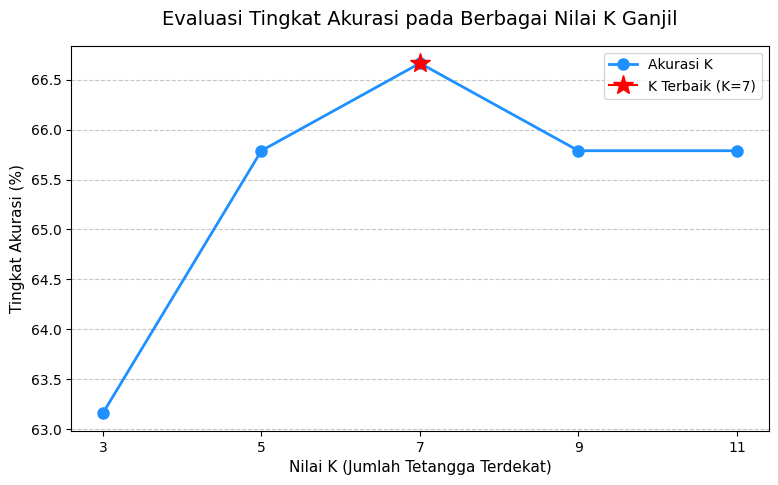


Sistem merekomendasikan K = 7 (Akurasi tertinggi: 66.67%)
Proses training dan prediksi model KNN utama berhasil dieksekusi!


In [59]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

print("\n--- 5 & 6. TRAINING KNN DAN KLASIFIKASI ---")

# Menyiapkan list/daftar untuk menyimpan nilai K dan akurasinya (untuk grafik)
k_values = []
accuracies = []

# Mencari nilai K terbaik secara otomatis dari rentang ganjil (1 hingga 11)
akurasi_tertinggi = 0
k_terbaik = 3

for k in range(3, 12, 2):
    knn_temp = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')
    knn_temp.fit(X_train, y_train)
    score = knn_temp.score(X_test, y_test)

    # Menyimpan data untuk grafik (ubah score ke format persentase)
    k_values.append(k)
    accuracies.append(score * 100)

    # Menentukan K terbaik
    if score > akurasi_tertinggi:
        akurasi_tertinggi = score
        k_terbaik = k

# =========================================================
# MENAMPILKAN GRAFIK PERBANDINGAN NILAI K
# =========================================================
plt.figure(figsize=(9, 5))
# Membuat garis grafik utama
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='dodgerblue', linewidth=2, markersize=8, label='Akurasi K')

# Memberi tanda khusus (warna merah) pada titik K yang paling optimal
plt.plot(k_terbaik, akurasi_tertinggi * 100, marker='*', color='red', markersize=15, label=f'K Terbaik (K={k_terbaik})')

# Pengaturan label dan tampilan grafik
plt.title('Evaluasi Tingkat Akurasi pada Berbagai Nilai K Ganjil', fontsize=14, pad=15)
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)', fontsize=11)
plt.ylabel('Tingkat Akurasi (%)', fontsize=11)
plt.xticks(k_values) # Memastikan sumbu X hanya menampilkan angka K yang diuji (1, 3, 5, dst)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()
# =========================================================

print(f"\nSistem merekomendasikan K = {k_terbaik} (Akurasi tertinggi: {akurasi_tertinggi*100:.2f}%)")

# Melatih Model Utama dengan K Terbaik
knn_model = KNeighborsClassifier(n_neighbors=k_terbaik, weights='distance', metric='euclidean')
knn_model.fit(X_train, y_train) # <- Proses model mengenali pola data latih

# Melakukan Prediksi / Voting (Klasifikasi)
y_pred = knn_model.predict(X_test) # <- Proses menebak data baru
print("Proses training dan prediksi model KNN utama berhasil dieksekusi!")


--- 7A. EVALUASI DAN CONFUSION MATRIX UNTUK SEMUA NILAI K ---

 CONFUSION MATRIX & METRIK KNN (K = 3) 
Akurasi (Accuracy)  : 63.16%
Presisi (Precision) : 66.94%
Recall              : 63.24%
F1-Score            : 63.44%


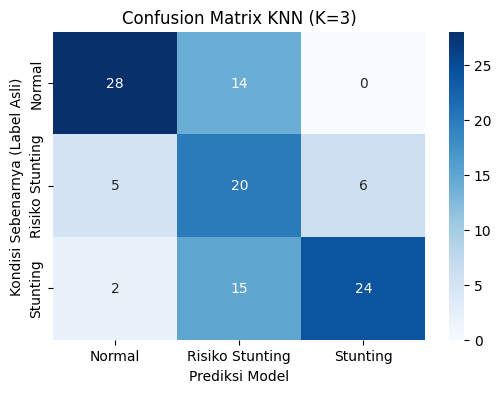


[ Detail Laporan Klasifikasi K=3 ]
                 precision    recall  f1-score   support

         Normal       0.80      0.67      0.73        42
Risiko Stunting       0.41      0.65      0.50        31
       Stunting       0.80      0.59      0.68        41

       accuracy                           0.63       114
      macro avg       0.67      0.63      0.63       114
   weighted avg       0.69      0.63      0.65       114




 CONFUSION MATRIX & METRIK KNN (K = 5) 
Akurasi (Accuracy)  : 65.79%
Presisi (Precision) : 68.00%
Recall              : 65.34%
F1-Score            : 65.45%


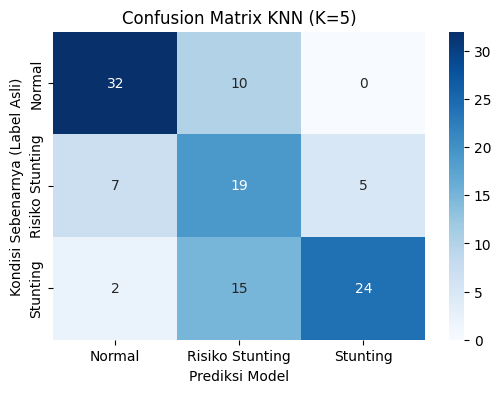


[ Detail Laporan Klasifikasi K=5 ]
                 precision    recall  f1-score   support

         Normal       0.78      0.76      0.77        42
Risiko Stunting       0.43      0.61      0.51        31
       Stunting       0.83      0.59      0.69        41

       accuracy                           0.66       114
      macro avg       0.68      0.65      0.65       114
   weighted avg       0.70      0.66      0.67       114




 CONFUSION MATRIX & METRIK KNN (K = 7) 
Akurasi (Accuracy)  : 66.67%
Presisi (Precision) : 68.52%
Recall              : 66.15%
F1-Score            : 66.29%


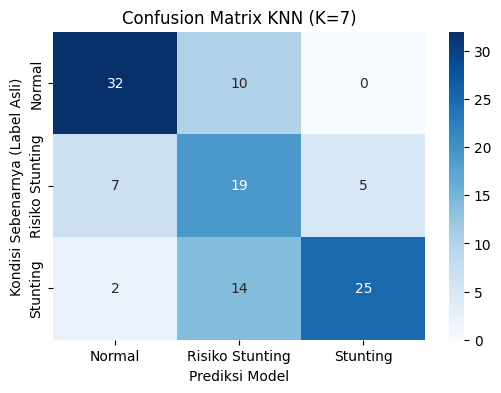


[ Detail Laporan Klasifikasi K=7 ]
                 precision    recall  f1-score   support

         Normal       0.78      0.76      0.77        42
Risiko Stunting       0.44      0.61      0.51        31
       Stunting       0.83      0.61      0.70        41

       accuracy                           0.67       114
      macro avg       0.69      0.66      0.66       114
   weighted avg       0.71      0.67      0.68       114




 CONFUSION MATRIX & METRIK KNN (K = 9) 
Akurasi (Accuracy)  : 65.79%
Presisi (Precision) : 68.59%
Recall              : 65.64%
F1-Score            : 65.79%


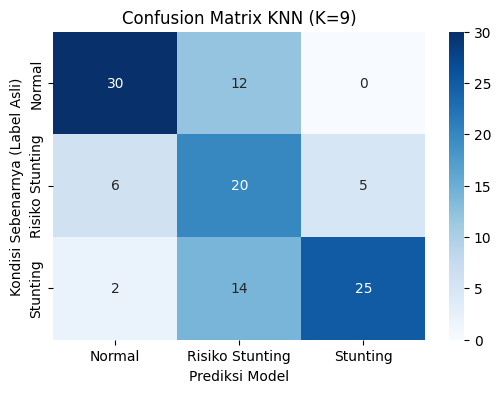


[ Detail Laporan Klasifikasi K=9 ]
                 precision    recall  f1-score   support

         Normal       0.79      0.71      0.75        42
Risiko Stunting       0.43      0.65      0.52        31
       Stunting       0.83      0.61      0.70        41

       accuracy                           0.66       114
      macro avg       0.69      0.66      0.66       114
   weighted avg       0.71      0.66      0.67       114




 CONFUSION MATRIX & METRIK KNN (K = 11) 
Akurasi (Accuracy)  : 65.79%
Presisi (Precision) : 69.47%
Recall              : 65.90%
F1-Score            : 65.91%


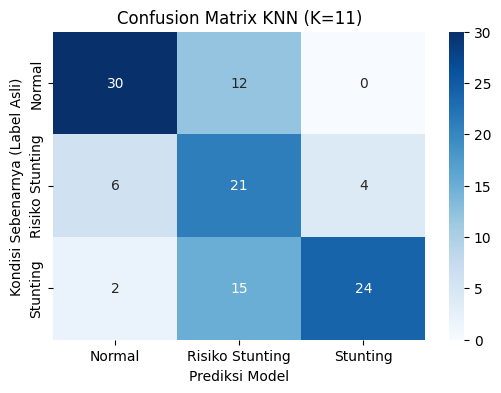


[ Detail Laporan Klasifikasi K=11 ]
                 precision    recall  f1-score   support

         Normal       0.79      0.71      0.75        42
Risiko Stunting       0.44      0.68      0.53        31
       Stunting       0.86      0.59      0.70        41

       accuracy                           0.66       114
      macro avg       0.69      0.66      0.66       114
   weighted avg       0.72      0.66      0.67       114





In [66]:
# ==========================================
# 7A. HASIL EVALUASI & CONFUSION MATRIX
# ==========================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
import matplotlib.pyplot as plt

print("\n--- 7A. EVALUASI DAN CONFUSION MATRIX UNTUK SEMUA NILAI K ---")

# Menentukan rentang K yang diuji (3 hingga 15 ganjil)
rentang_k = range(3, 12, 2)

for k in rentang_k:
    print("\n" + "="*55)
    print(f" CONFUSION MATRIX & METRIK KNN (K = {k}) ")
    print("="*55)

    # Melatih model khusus untuk K saat ini
    knn_eval = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')
    knn_eval.fit(X_train, y_train)

    # Melakukan Prediksi
    y_pred_eval = knn_eval.predict(X_test)

    # Menghitung Metrik Evaluasi
    akurasi = accuracy_score(y_test, y_pred_eval)
    presisi = precision_score(y_test, y_pred_eval, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred_eval, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred_eval, average='macro', zero_division=0)

    print(f"Akurasi (Accuracy)  : {akurasi * 100:.2f}%")
    print(f"Presisi (Precision) : {presisi * 100:.2f}%")
    print(f"Recall              : {recall * 100:.2f}%")
    print(f"F1-Score            : {f1 * 100:.2f}%")

    # Visualisasi Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_eval)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=knn_eval.classes_,
                yticklabels=knn_eval.classes_)
    plt.title(f'Confusion Matrix KNN (K={k})')
    plt.xlabel('Prediksi Model')
    plt.ylabel('Kondisi Sebenarnya (Label Asli)')
    plt.show()

    # Laporan Klasifikasi Detail
    print(f"\n[ Detail Laporan Klasifikasi K={k} ]")
    print(classification_report(y_test, y_pred_eval, zero_division=0))
    print("\n")


--- 7B. 5-FOLD CROSS VALIDATION UNTUK SEMUA NILAI K ---

[ Menguji Kestabilan Model untuk K = 3 ]
  Akurasi tiap lipatan (Fold 1-5): [69.3  59.65 60.18 63.72 63.72]
  --> Rata-rata Akurasi 5-Fold CV: 63.31%

[ Menguji Kestabilan Model untuk K = 5 ]
  Akurasi tiap lipatan (Fold 1-5): [66.67 54.39 61.06 63.72 63.72]
  --> Rata-rata Akurasi 5-Fold CV: 61.91%

[ Menguji Kestabilan Model untuk K = 7 ]
  Akurasi tiap lipatan (Fold 1-5): [69.3  56.14 69.03 58.41 61.06]
  --> Rata-rata Akurasi 5-Fold CV: 62.79%

[ Menguji Kestabilan Model untuk K = 9 ]
  Akurasi tiap lipatan (Fold 1-5): [68.42 57.02 69.03 60.18 63.72]
  --> Rata-rata Akurasi 5-Fold CV: 63.67%

[ Menguji Kestabilan Model untuk K = 11 ]
  Akurasi tiap lipatan (Fold 1-5): [68.42 57.89 68.14 61.95 62.83]
  --> Rata-rata Akurasi 5-Fold CV: 63.85%


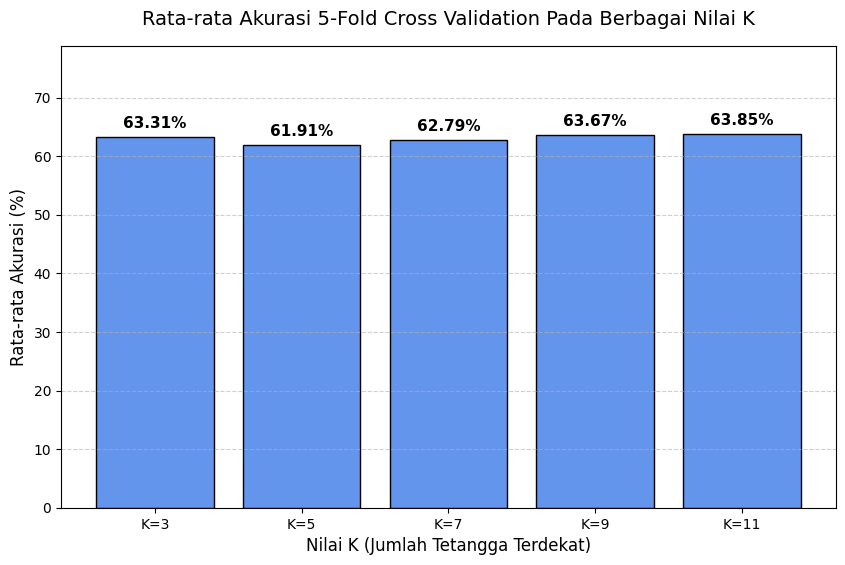

In [69]:
# ==========================================
# 7B. PENGUJIAN KESTABILAN MODEL (CROSS VALIDATION)
# ==========================================
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import matplotlib.pyplot as plt

print("\n--- 7B. 5-FOLD CROSS VALIDATION UNTUK SEMUA NILAI K ---")

# Menentukan rentang K yang diuji (3 hingga 15 ganjil)
rentang_k = range(3, 12, 2)

# Menyiapkan list untuk menampung data grafik
k_labels = []
cv_mean_scores = []

for k in rentang_k:
    print(f"\n[ Menguji Kestabilan Model untuk K = {k} ]")

    # Inisiasi model untuk cross validation
    knn_cv = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')

    # Melakukan 5-Fold Cross Validation menggunakan seluruh dataset (X_normalized_df, y)
    cv_scores = cross_val_score(knn_cv, X_normalized_df, y, cv=5, scoring='accuracy')
    rata_rata_cv = cv_scores.mean() * 100

    # Menyimpan data untuk grafik
    k_labels.append(f"K={k}")
    cv_mean_scores.append(rata_rata_cv)

    # Menampilkan hasil berupa teks
    print(f"  Akurasi tiap lipatan (Fold 1-5): {np.round(cv_scores * 100, 2)}")
    print(f"  --> Rata-rata Akurasi 5-Fold CV: {rata_rata_cv:.2f}%")

# =========================================================
# MENAMPILKAN VISUALISASI DIAGRAM BATANG
# =========================================================
plt.figure(figsize=(10, 6))

# Membuat diagram batang
bars = plt.bar(k_labels, cv_mean_scores, color='cornflowerblue', edgecolor='black')

# Menambahkan angka persentase tepat di atas setiap batang
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.2f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# Pengaturan label dan tampilan grafik
plt.title('Rata-rata Akurasi 5-Fold Cross Validation Pada Berbagai Nilai K', fontsize=14, pad=15)
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)', fontsize=12)
plt.ylabel('Rata-rata Akurasi (%)', fontsize=12)
plt.ylim(0, max(cv_mean_scores) + 15) # Memberi ruang ekstra di atas agar angka tidak terpotong
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Menampilkan grafik
plt.show()

In [57]:
from IPython.display import display

print("\n--- 8. OUTPUT SISTEM (Komparasi Prediksi) ---")

# Mengambil 5 index pertama dari data pengujian
lima_index_uji = X_test.head(5).index

# Mengambil kembali data asli (sebelum dinormalisasi) agar mudah dibaca manusia
tabel_tampil = df_gabungan.loc[lima_index_uji, fitur_knn].copy()

# Mengambil 5 hasil prediksi untuk disandingkan
hasil_prediksi_5 = knn_model.predict(X_test.head(5))

# Mempercantik Tampilan Tabel
tabel_tampil.insert(0, 'Sampel Uji', [f'Balita Uji {i+1}' for i in range(5)])
tabel_tampil['Status Gizi (ASLI)'] = y_test.head(5).values
tabel_tampil['Status Gizi (PREDIKSI)'] = [status.upper() for status in hasil_prediksi_5]

print("\nTabel Pembuktian Prediksi Sistem:")
display(tabel_tampil)


--- 8. OUTPUT SISTEM (Komparasi Prediksi) ---

Tabel Pembuktian Prediksi Sistem:


,Sampel Uji,Usia Saat Ukur,Berat,Tinggi,Jenis Kelamin Encoded,Total Skor (A-F),Status Gizi (ASLI),Status Gizi (PREDIKSI)
540,Balita Uji 1,20,10.0,81.5,0,141,Normal,NORMAL
525,Balita Uji 2,5,7.2,63.7,0,123,Normal,NORMAL
234,Balita Uji 3,7,7.8,66.3,0,135,Normal,RISIKO STUNTING
526,Balita Uji 4,5,6.5,63.0,1,76,Normal,NORMAL
490,Balita Uji 5,8,8.0,68.1,1,178,Normal,NORMAL
